# Digital Image Processing Lab — Lab Task #04
## Geometric Transformations with Custom Inputs

**Student Name:** Fatima Arshad  
**Roll Number:** 2024-SE-24  
**Department:** Software Engineering  
**Semester:** Fifth  
**University:** The University of Azad Jammu and Kashmir  
**Lab Instructor:** Engr. Fahad Nisar  
**Session:** 2024–28 (SE)

### Objective
Create one reusable `transform()` function that accepts an image, an operation name, and custom parameters. Validate inputs and perform scaling, cropping, flipping, translation, and rotation.

> **Input image note:** `input_image.png` is a generated sample image included so this project runs immediately. If your instructor requires your own photograph, place it in this folder and update `IMAGE_PATH` below.

## 1. Import libraries

In [1]:
from pathlib import Path
import math
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

np.set_printoptions(suppress=True)
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)
IMAGE_PATH = Path("input_image.png")
MAX_OUTPUT_PIXELS = 25_000_000  # sensible safety limit: 25 million pixels

print("Libraries imported successfully.")
print("OpenCV version:", cv2.__version__)

Libraries imported successfully.
OpenCV version: 5.0.0


## 2. Load and validate the image

Width: 480
Height: 360
Array shape: (360, 480, 3)
Data type: uint8


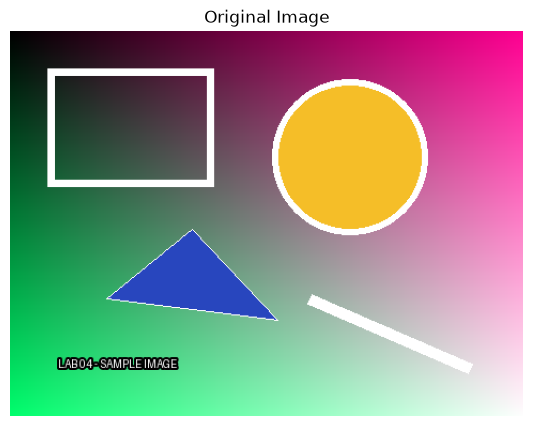

In [2]:
def load_valid_image(path):
    path = Path(path)
    if not path.exists() or not path.is_file():
        raise FileNotFoundError(f"Image file does not exist: {path}")
    image = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError("The file exists, but it could not be decoded as an image.")
    if image.size == 0 or image.shape[0] == 0 or image.shape[1] == 0:
        raise ValueError("The image has zero dimensions.")
    # OpenCV loads BGR; convert once to RGB for consistent display and processing.
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

original = load_valid_image(IMAGE_PATH)
height, width = original.shape[:2]
print("Width:", width)
print("Height:", height)
print("Array shape:", original.shape)
print("Data type:", original.dtype)

plt.figure(figsize=(8, 5))
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")
plt.show()

## 3. Reusable transformation function and validation

In [3]:
INTERPOLATIONS = {
    "nearest": cv2.INTER_NEAREST,
    "bilinear": cv2.INTER_LINEAR,
    "bicubic": cv2.INTER_CUBIC,
    "lanczos": cv2.INTER_LANCZOS4,
}

def _finite_number(value, name):
    # bool is a subclass of int, but should not count as a numeric parameter here.
    if isinstance(value, (bool, np.bool_)):
        raise ValueError(f"{name} must be a finite number, not True/False.")
    try:
        number = float(value)
    except (TypeError, ValueError):
        raise ValueError(f"{name} must be numeric.")
    if not math.isfinite(number):
        raise ValueError(f"{name} must be finite (not NaN or infinity).")
    return number

def _integer(value, name):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, (int, np.integer)):
        raise ValueError(f"{name} must be an integer.")
    return int(value)

def _check_output_size(new_width, new_height):
    if new_width < 1 or new_height < 1:
        raise ValueError("Output width and height must each be at least 1 pixel.")
    if new_width * new_height > MAX_OUTPUT_PIXELS:
        raise ValueError(f"Output is too large. Maximum allowed pixels: {MAX_OUTPUT_PIXELS:,}.")

def _validate_image(image):
    if not isinstance(image, np.ndarray):
        raise ValueError("Image must be a NumPy array.")
    if image.size == 0 or image.ndim != 3 or image.shape[2] != 3:
        raise ValueError("Image must be a non-empty RGB image with 3 channels.")
    if image.shape[0] < 1 or image.shape[1] < 1:
        raise ValueError("Image dimensions must be nonzero.")

def transform(image, operation, **params):
    """Apply one geometric transformation to an RGB image.

    Supported operations: scale, crop, flip, translate, rotate.
    Parameters are supplied by the caller, not hard-coded in this function.
    The input image is never modified.
    """
    _validate_image(image)
    if not isinstance(operation, str):
        raise ValueError("Operation name must be text.")
    op = operation.strip().lower()
    h, w = image.shape[:2]

    if op == "scale":
        required = {"sx", "sy", "interpolation"}
        if not required.issubset(params):
            raise ValueError(f"Scale requires parameters: {sorted(required)}")
        sx = _finite_number(params["sx"], "sx")
        sy = _finite_number(params["sy"], "sy")
        if sx <= 0 or sy <= 0:
            raise ValueError("Scale factors must be greater than zero.")
        interpolation = str(params["interpolation"]).lower()
        if interpolation not in INTERPOLATIONS:
            raise ValueError("Unsupported interpolation. Choose nearest, bilinear, bicubic, or lanczos.")
        new_w, new_h = int(round(w * sx)), int(round(h * sy))
        _check_output_size(new_w, new_h)
        return cv2.resize(image, (new_w, new_h), interpolation=INTERPOLATIONS[interpolation])

    elif op == "crop":
        required = {"left", "top", "right", "bottom"}
        if not required.issubset(params):
            raise ValueError(f"Crop requires parameters: {sorted(required)}")
        left = _integer(params["left"], "left")
        top = _integer(params["top"], "top")
        right = _integer(params["right"], "right")
        bottom = _integer(params["bottom"], "bottom")
        if not (0 <= left < right <= w and 0 <= top < bottom <= h):
            raise ValueError(f"Invalid crop. Require 0 <= left < right <= {w} and 0 <= top < bottom <= {h}.")
        result = image[top:bottom, left:right].copy()  # right and bottom are exclusive
        _check_output_size(result.shape[1], result.shape[0])
        return result

    elif op == "flip":
        if "direction" not in params:
            raise ValueError("Flip requires direction: horizontal, vertical, or both.")
        direction = str(params["direction"]).lower()
        flip_codes = {"horizontal": 1, "vertical": 0, "both": -1}
        if direction not in flip_codes:
            raise ValueError("Unsupported flip direction. Choose horizontal, vertical, or both.")
        return cv2.flip(image, flip_codes[direction])

    elif op == "translate":
        if not {"tx", "ty"}.issubset(params):
            raise ValueError("Translation requires tx and ty.")
        tx = _finite_number(params["tx"], "tx")
        ty = _finite_number(params["ty"], "ty")
        matrix = np.float32([[1, 0, tx], [0, 1, ty]])
        # Keep original canvas size. Areas moved outside are clipped; newly exposed areas are black.
        return cv2.warpAffine(image, matrix, (w, h), flags=cv2.INTER_LINEAR,
                              borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

    elif op == "rotate":
        if not {"angle", "expand"}.issubset(params):
            raise ValueError("Rotation requires angle and expand.")
        angle = _finite_number(params["angle"], "angle")
        expand = params["expand"]
        if not isinstance(expand, (bool, np.bool_)):
            raise ValueError("expand must be True or False.")
        center = (w / 2.0, h / 2.0)
        matrix = cv2.getRotationMatrix2D(center, angle, 1.0)
        if expand:
            cos_a = abs(matrix[0, 0])
            sin_a = abs(matrix[0, 1])
            new_w = int(math.ceil(h * sin_a + w * cos_a))
            new_h = int(math.ceil(h * cos_a + w * sin_a))
            _check_output_size(new_w, new_h)
            matrix[0, 2] += (new_w - w) / 2.0
            matrix[1, 2] += (new_h - h) / 2.0
        else:
            new_w, new_h = w, h
        # OpenCV positive angle is counter-clockwise in the displayed image coordinate system.
        return cv2.warpAffine(image, matrix, (new_w, new_h),
                              flags=cv2.INTER_LINEAR,
                              borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

    else:
        raise ValueError("Unknown operation. Choose scale, crop, flip, translate, or rotate.")

print("transform() function is ready.")

transform() function is ready.


## 4. Helper to display and save results

In [17]:
def show_and_save(result, title, filename):
    output_path = OUTPUT_DIR / filename
    # Save RGB correctly with PIL.
    Image.fromarray(result).save(output_path)
    h, w = result.shape[:2]
    plt.figure(figsize=(7, 4.5))
    plt.imshow(result)
    plt.title(f"{title} | Output: {w} x {h}")
    plt.axis("off")
    plt.show()
    print(f"Saved: {output_path} | shape: {result.shape}")
    return output_path

def compare_images(original_image, transformed_image, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].imshow(original_image)
    axes[0].set_title(f"Original ({original_image.shape[1]} x {original_image.shape[0]})")
    axes[1].imshow(transformed_image)
    axes[1].set_title(f"{title} ({transformed_image.shape[1]} x {transformed_image.shape[0]})")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 5. Scaling / resizing — enlargement and reduction

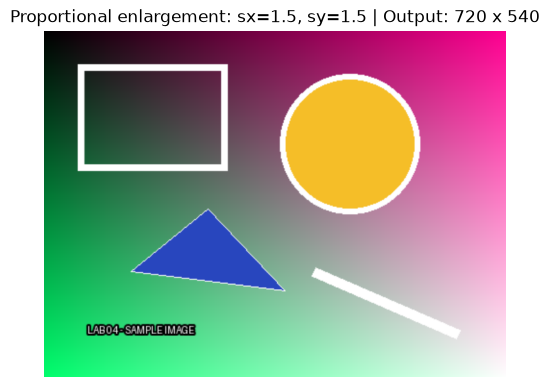

Saved: outputs\01_scale_up.png | shape: (540, 720, 3)


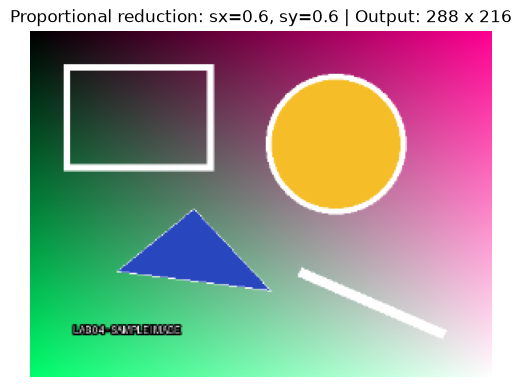

Saved: outputs\02_scale_down.png | shape: (216, 288, 3)


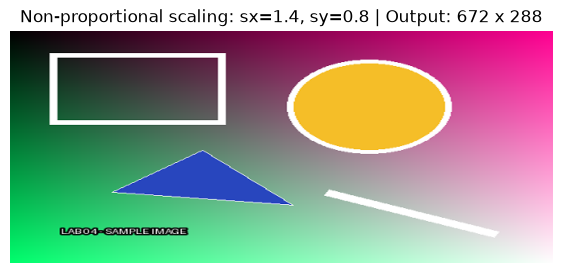

Saved: outputs\03_scale_nonproportional.png | shape: (288, 672, 3)


WindowsPath('outputs/03_scale_nonproportional.png')

In [18]:
# Proportional enlargement: same factor in both directions
scaled_up = transform(original, "scale", sx=1.5, sy=1.5, interpolation="bilinear")
show_and_save(scaled_up, "Proportional enlargement: sx=1.5, sy=1.5", "01_scale_up.png")

# Proportional reduction
scaled_down = transform(original, "scale", sx=0.6, sy=0.6, interpolation="bilinear")
show_and_save(scaled_down, "Proportional reduction: sx=0.6, sy=0.6", "02_scale_down.png")

# Non-proportional scaling changes aspect ratio
scaled_nonproportional = transform(original, "scale", sx=1.4, sy=0.8, interpolation="bicubic")
show_and_save(scaled_nonproportional, "Non-proportional scaling: sx=1.4, sy=0.8", "03_scale_nonproportional.png")

## 6. Cropping

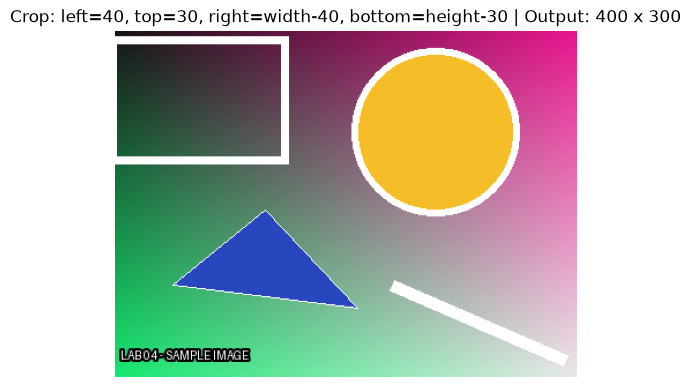

Saved: outputs\04_crop.png | shape: (300, 400, 3)


WindowsPath('outputs/04_crop.png')

In [6]:
h, w = original.shape[:2]
cropped = transform(original, "crop", left=40, top=30, right=w-40, bottom=h-30)
show_and_save(cropped, "Crop: left=40, top=30, right=width-40, bottom=height-30", "04_crop.png")

## 7. Flipping — all three directions

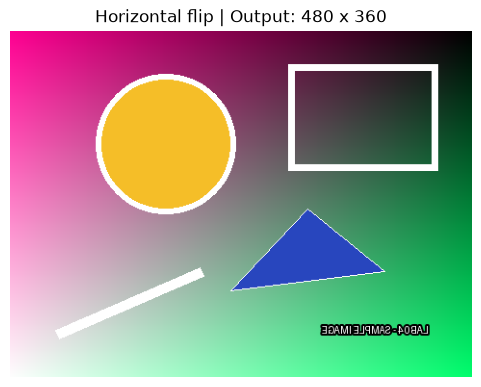

Saved: outputs\05_flip_horizontal.png | shape: (360, 480, 3)


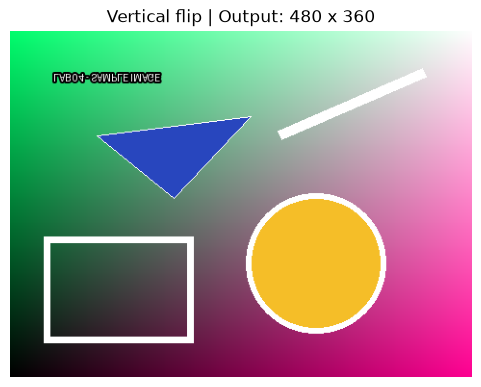

Saved: outputs\06_flip_vertical.png | shape: (360, 480, 3)


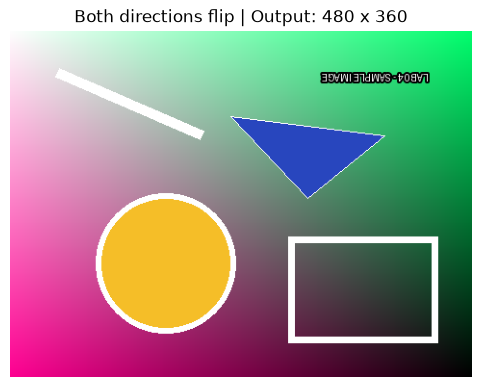

Saved: outputs\07_flip_both.png | shape: (360, 480, 3)


WindowsPath('outputs/07_flip_both.png')

In [7]:
flip_horizontal = transform(original, "flip", direction="horizontal")
flip_vertical = transform(original, "flip", direction="vertical")
flip_both = transform(original, "flip", direction="both")
show_and_save(flip_horizontal, "Horizontal flip", "05_flip_horizontal.png")
show_and_save(flip_vertical, "Vertical flip", "06_flip_vertical.png")
show_and_save(flip_both, "Both directions flip", "07_flip_both.png")

## 8. Translation — opposite directions and zero offset

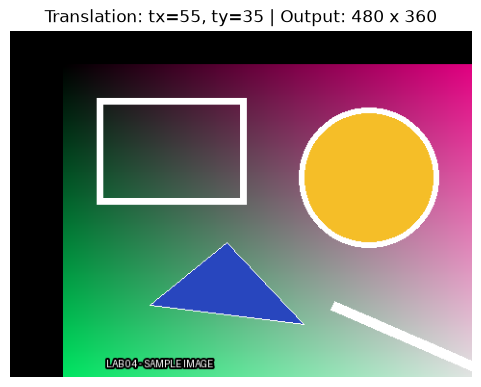

Saved: outputs\08_translate_right_down.png | shape: (360, 480, 3)


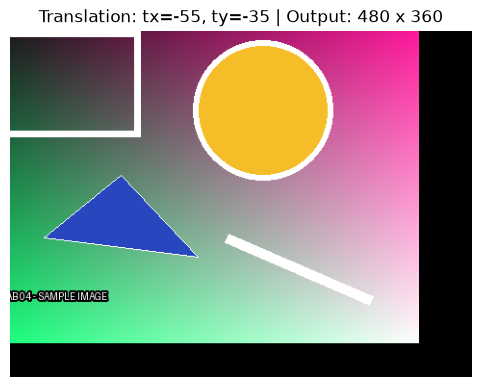

Saved: outputs\09_translate_left_up.png | shape: (360, 480, 3)


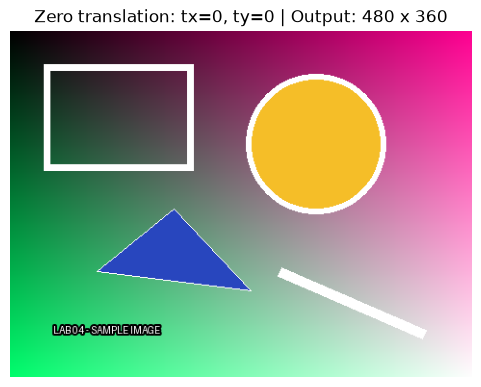

Saved: outputs\10_translate_zero.png | shape: (360, 480, 3)


WindowsPath('outputs/10_translate_zero.png')

In [8]:
shift_right_down = transform(original, "translate", tx=55, ty=35)
show_and_save(shift_right_down, "Translation: tx=55, ty=35", "08_translate_right_down.png")

shift_left_up = transform(original, "translate", tx=-55, ty=-35)
show_and_save(shift_left_up, "Translation: tx=-55, ty=-35", "09_translate_left_up.png")

zero_translation = transform(original, "translate", tx=0, ty=0)
show_and_save(zero_translation, "Zero translation: tx=0, ty=0", "10_translate_zero.png")

## 9. Rotation — positive, negative, and expanded canvas

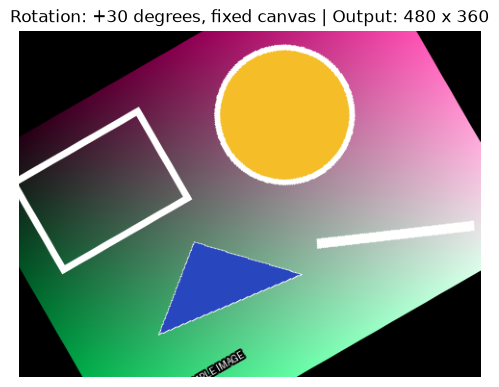

Saved: outputs\11_rotate_positive_fixed.png | shape: (360, 480, 3)


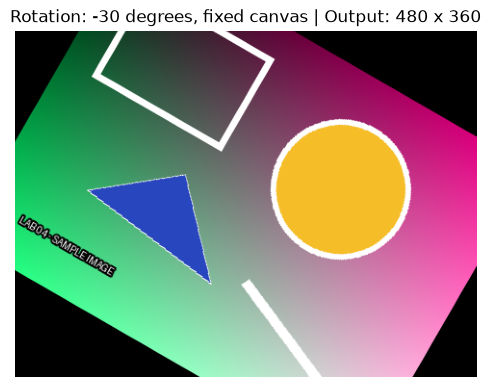

Saved: outputs\12_rotate_negative_fixed.png | shape: (360, 480, 3)


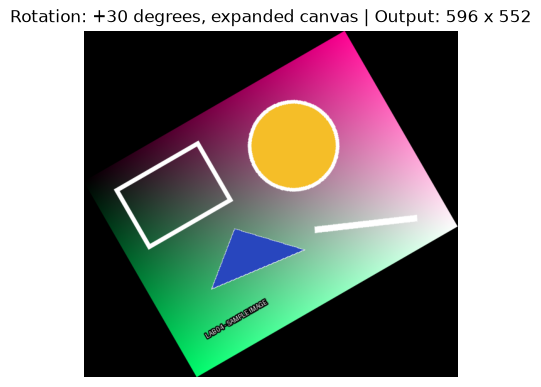

Saved: outputs\13_rotate_expanded.png | shape: (552, 596, 3)


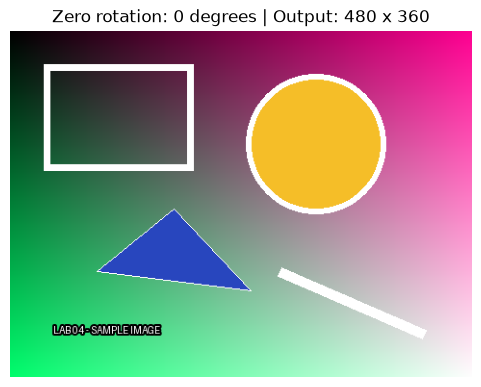

Saved: outputs\14_rotate_zero.png | shape: (360, 480, 3)


WindowsPath('outputs/14_rotate_zero.png')

In [9]:
rotated_positive = transform(original, "rotate", angle=30, expand=False)
show_and_save(rotated_positive, "Rotation: +30 degrees, fixed canvas", "11_rotate_positive_fixed.png")

rotated_negative = transform(original, "rotate", angle=-30, expand=False)
show_and_save(rotated_negative, "Rotation: -30 degrees, fixed canvas", "12_rotate_negative_fixed.png")

rotated_expanded = transform(original, "rotate", angle=30, expand=True)
show_and_save(rotated_expanded, "Rotation: +30 degrees, expanded canvas", "13_rotate_expanded.png")

rotated_zero = transform(original, "rotate", angle=0, expand=False)
show_and_save(rotated_zero, "Zero rotation: 0 degrees", "14_rotate_zero.png")

## 10. Interpolation comparison on the same enlarged image patch

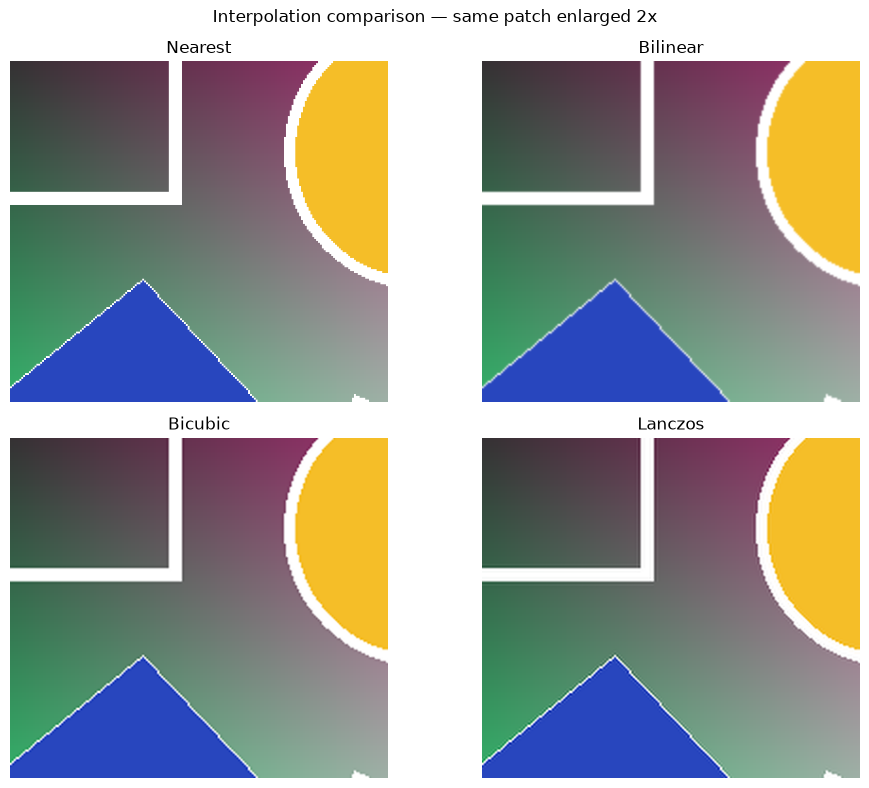

Nearest-neighbour: sharp block-like pixels; no averaging.
Bilinear: smoother result; uses nearby pixels and may look slightly soft.
Bicubic: smoother detail; uses a larger neighbourhood than bilinear.
Lanczos: often preserves fine detail well, but can create slight ringing near sharp edges.


In [10]:
# Use the same crop and scale factors for a fair interpolation comparison.
patch = transform(original, "crop", left=100, top=70, right=300, bottom=250)
interpolation_results = {}
for method in ["nearest", "bilinear", "bicubic", "lanczos"]:
    interpolation_results[method] = transform(patch, "scale", sx=2.0, sy=2.0, interpolation=method)
    Image.fromarray(interpolation_results[method]).save(OUTPUT_DIR / f"15_interpolation_{method}.png")

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, method in zip(axes.flat, ["nearest", "bilinear", "bicubic", "lanczos"]):
    ax.imshow(interpolation_results[method])
    ax.set_title(method.capitalize())
    ax.axis("off")
plt.suptitle("Interpolation comparison — same patch enlarged 2x")
plt.tight_layout()
plt.show()
print("Nearest-neighbour: sharp block-like pixels; no averaging.")
print("Bilinear: smoother result; uses nearby pixels and may look slightly soft.")
print("Bicubic: smoother detail; uses a larger neighbourhood than bilinear.")
print("Lanczos: often preserves fine detail well, but can create slight ringing near sharp edges.")

## 11. Input validation — rejected examples for every operation

In [11]:
def show_rejection(label, function):
    try:
        function()
        print(f"FAIL — {label}: invalid input was accepted.")
    except (ValueError, FileNotFoundError, TypeError) as error:
        print(f"PASS — {label}: rejected correctly -> {error}")

show_rejection("Scale with zero factor",
               lambda: transform(original, "scale", sx=0, sy=1, interpolation="bilinear"))
show_rejection("Crop with invalid coordinates",
               lambda: transform(original, "crop", left=200, top=20, right=100, bottom=200))
show_rejection("Flip with unsupported direction",
               lambda: transform(original, "flip", direction="diagonal"))
show_rejection("Translation with NaN offset",
               lambda: transform(original, "translate", tx=float("nan"), ty=5))
show_rejection("Rotation with nonnumeric angle",
               lambda: transform(original, "rotate", angle="thirty", expand=False))

# Additional validation examples
show_rejection("Unsupported interpolation",
               lambda: transform(original, "scale", sx=2, sy=2, interpolation="fastest"))
show_rejection("Unknown operation",
               lambda: transform(original, "shear", amount=10))
show_rejection("Missing rotation parameter",
               lambda: transform(original, "rotate", angle=45))
show_rejection("Infinite translation",
               lambda: transform(original, "translate", tx=float("inf"), ty=0))

PASS — Scale with zero factor: rejected correctly -> Scale factors must be greater than zero.
PASS — Crop with invalid coordinates: rejected correctly -> Invalid crop. Require 0 <= left < right <= 480 and 0 <= top < bottom <= 360.
PASS — Flip with unsupported direction: rejected correctly -> Unsupported flip direction. Choose horizontal, vertical, or both.
PASS — Translation with NaN offset: rejected correctly -> tx must be finite (not NaN or infinity).
PASS — Rotation with nonnumeric angle: rejected correctly -> angle must be numeric.
PASS — Unsupported interpolation: rejected correctly -> Unsupported interpolation. Choose nearest, bilinear, bicubic, or lanczos.
PASS — Unknown operation: rejected correctly -> Unknown operation. Choose scale, crop, flip, translate, or rotate.
PASS — Missing rotation parameter: rejected correctly -> Rotation requires angle and expand.
PASS — Infinite translation: rejected correctly -> tx must be finite (not NaN or infinity).


## 12. Identity checks — expected vs actual behaviour

In [12]:
def is_identical(a, b):
    return a.shape == b.shape and np.array_equal(a, b)

identity_cases = [
    ("Scale factors of one", original,
     transform(original, "scale", sx=1, sy=1, interpolation="nearest")),
    ("Zero translation", original,
     transform(original, "translate", tx=0, ty=0)),
    ("Zero rotation", original,
     transform(original, "rotate", angle=0, expand=False)),
]
identity_rows = []
for name, expected, actual in identity_cases:
    passed = is_identical(expected, actual)
    identity_rows.append((name, "Image should remain unchanged", "Unchanged" if passed else "Changed",
                          "Pass" if passed else "Fail"))
for row in identity_rows:
    print(f"{row[0]} | Expected: {row[1]} | Actual: {row[2]} | {row[3]}")

Scale factors of one | Expected: Image should remain unchanged | Actual: Unchanged | Pass
Zero translation | Expected: Image should remain unchanged | Actual: Unchanged | Pass
Zero rotation | Expected: Image should remain unchanged | Actual: Unchanged | Pass


## 13. Custom user input through notebook prompts

In [13]:
def run_custom_operation():
    """Run this function when you want to enter your own values in the notebook."""
    print("Operations: scale, crop, flip, translate, rotate")
    operation = input("Enter operation name: ").strip().lower()
    try:
        if operation == "scale":
            sx = float(input("Enter horizontal scale factor sx: "))
            sy = float(input("Enter vertical scale factor sy: "))
            method = input("Interpolation (nearest/bilinear/bicubic/lanczos): ").strip().lower()
            result = transform(original, operation, sx=sx, sy=sy, interpolation=method)
        elif operation == "crop":
            left = int(input("Left: "))
            top = int(input("Top: "))
            right = int(input("Right: "))
            bottom = int(input("Bottom: "))
            result = transform(original, operation, left=left, top=top, right=right, bottom=bottom)
        elif operation == "flip":
            direction = input("Direction (horizontal/vertical/both): ").strip().lower()
            result = transform(original, operation, direction=direction)
        elif operation == "translate":
            tx = float(input("Horizontal offset tx: "))
            ty = float(input("Vertical offset ty: "))
            result = transform(original, operation, tx=tx, ty=ty)
        elif operation == "rotate":
            angle = float(input("Angle in degrees: "))
            expand_text = input("Expand canvas? (yes/no): ").strip().lower()
            if expand_text not in ("yes", "no"):
                raise ValueError("Enter yes or no for canvas expansion.")
            result = transform(original, operation, angle=angle, expand=(expand_text == "yes"))
        else:
            raise ValueError("Unknown operation.")
        show_and_save(result, f"Custom operation: {operation}", "custom_result.png")
    except (ValueError, TypeError) as error:
        print("Input error:", error)
        print("Please run run_custom_operation() again and enter valid values.")

print("To enter your own values, run this cell and then call: run_custom_operation()")
# Example call (uncomment when you want to enter values interactively):
# run_custom_operation()

To enter your own values, run this cell and then call: run_custom_operation()


## 14. Short conceptual explanations

### Image coordinates vs array indexing
Image coordinates are commonly written as `(x, y)`, where `x` is the horizontal column and `y` is the vertical row. NumPy indexing is `[row, column]`, so a pixel is accessed as `image[y, x]`.

### Aspect-ratio distortion
Aspect ratio is width divided by height. If horizontal and vertical scale factors are different, the image stretches or becomes compressed. Equal factors preserve the original aspect ratio.

### Rotation canvas expansion
Without expansion, the rotated image stays on the original width and height, so corner areas may be clipped. With expansion, the output canvas is enlarged to fit the rotated image.

### Translation clipping and exposed background
Translation moves pixels horizontally by `tx` and vertically by `ty`. The canvas remains the same size. Pixels shifted beyond its boundary are clipped, and newly exposed areas are filled with black.

### Positive-angle direction
In OpenCV, a positive rotation angle rotates counter-clockwise in the displayed image coordinate system; a negative angle rotates clockwise.

## 15. Final output checklist

In [14]:
print("Original image remains unchanged:", is_identical(original, load_valid_image(IMAGE_PATH)))
print("Saved output files:")
for file in sorted(OUTPUT_DIR.glob("*.png")):
    print("-", file.name)

Original image remains unchanged: True
Saved output files:
- 01_scale_up.png
- 02_scale_down.png
- 03_scale_nonproportional.png
- 04_crop.png
- 05_flip_horizontal.png
- 06_flip_vertical.png
- 07_flip_both.png
- 08_translate_right_down.png
- 09_translate_left_up.png
- 10_translate_zero.png
- 11_rotate_positive_fixed.png
- 12_rotate_negative_fixed.png
- 13_rotate_expanded.png
- 14_rotate_zero.png
- 15_interpolation_bicubic.png
- 15_interpolation_bilinear.png
- 15_interpolation_lanczos.png
- 15_interpolation_nearest.png


## Conclusion
The lab implements a reusable transformation function with custom parameters and internal validation. Scaling, cropping, flipping, translation, and rotation were demonstrated. Invalid inputs were rejected with readable error messages, interpolation methods were compared, and identity cases were checked. The original image was kept unchanged and transformed results were saved in the `outputs` folder.

**Submission reminder:** Restart the kernel and run all cells from top to bottom before submitting. Include the notebook, input image, and outputs in your accessible project repository. Do not submit a virtual environment or cache folders.